In [1]:
# loading data 
import pandas as pd
import matplotlib.pyplot as plt

from runtime_sim import config

sections = pd.read_csv(config.PROCESSED_DIR / "sections.csv", dtype={"rid": str, "sched_dep_from": str})
print(f"{len(sections):,} sections")
sections.head()

159,648 sections


,rid,date,from_loc,to_loc,sched_leave,sched_reach,actual_leave,actual_reach,dwell_delay_at_to,planned_run,actual_run,run_delay,sched_dep_from,peak
0,202608037678463,2026-08-03,WAT,CLJ,413.0,420.0,412.0,420.0,NaN,7.0,8.0,1.0,0653,False
1,202608037678463,2026-08-03,CLJ,SUR,420.0,430.0,420.0,429.0,0.0,10.0,9.0,-1.0,0653,False
2,202608037678463,2026-08-03,SUR,WBY,431.0,441.0,430.0,439.0,2.0,10.0,9.0,-1.0,0653,False
3,202608037678463,2026-08-03,WBY,WOK,441.0,446.0,441.0,446.0,-1.0,5.0,5.0,0.0,0653,False
4,202608037678463,2026-08-03,WOK,BKO,450.0,456.0,449.0,453.0,3.0,6.0,4.0,-2.0,0653,False


In [5]:
# complete description of data 
sections[["planned_run", "actual_run", "run_delay", "dwell_delay_at_to"]].describe().round(2)

,planned_run,actual_run,run_delay,dwell_delay_at_to
count,159648.00,159648.00,159648.00,138569.00
mean,7.18,6.63,-0.55,0.96
std,4.94,6.73,4.11,1.56
min,1.00,0.00,-23.00,-24.00
25%,4.00,3.00,-1.00,0.00
50%,6.00,5.00,-1.00,1.00
75%,8.00,8.00,0.00,2.00
max,83.00,1392.00,1388.00,88.00


In [8]:
# stations in data 
sections["from_loc"].value_counts().head(40)

from_loc
WAT    12999
WOK    10788
CLJ     8205
SUR     6095
WBY     4304
WAL     4302
WYB     4290
BKO     3753
FTN     3344
GLD     3243
GOD     3229
PMS     3044
FNB     2995
FLE     2992
BSK     2895
HSL     2646
BFN     2558
ESH     2535
HER     2517
VXH     2511
HAV     2487
WIM     2482
PTR     2480
EAD     2355
WIN     2239
FNC     2136
HLS     2072
WNF     1957
HOK     1956
AHV     1912
AHT     1909
FNH     1885
ESL     1440
WPL     1394
BTY     1388
LIP     1364
LIS     1361
WTY     1355
MLF     1352
ADV     1274
Name: count, dtype: int64

In [10]:
# Stations between Waterloo and Woking, in order along the line
route = sections[sections["from_loc"].isin(config.ROUTE_STATIONS)
                 & sections["to_loc"].isin(config.ROUTE_STATIONS)].copy()
print(f"{len(route):,} sections on the WAT-WOK stretch ({len(route) / len(sections):.0%} of all)")
route.groupby(["from_loc", "to_loc"]).size().sort_values(ascending=False).head(20)

55,023 sections on the WAT-WOK stretch (34% of all)


from_loc  to_loc
WAT       CLJ       5682
WBY       WOK       4304
WAL       WYB       4302
WAT       WOK       3877
CLJ       WOK       2905
          SUR       2636
SUR       ESH       2530
HER       WAL       2517
ESH       HER       2515
WAT       VXH       2508
WYB       BFN       2506
WIM       SUR       2455
VXH       CLJ       2454
BFN       WBY       2386
CLJ       EAD       2356
EAD       WIM       2355
SUR       WAL       1774
WYB       WOK       1681
SUR       WBY       1667
WAT       SUR        929
dtype: int64

In [11]:
weird = sections[sections["actual_run"] > 120]
print(f"{len(weird)} sections with an actual run time over 2 hours")
weird[["rid", "date", "from_loc", "to_loc", "sched_leave", "sched_reach",
       "actual_leave", "actual_reach", "planned_run", "actual_run"]]

7 sections with an actual run time over 2 hours


,rid,date,from_loc,to_loc,sched_leave,sched_reach,actual_leave,actual_reach,planned_run,actual_run
19254,202608127680336,2026-08-12,PKS,POO,1417.0,1421.0,28.0,1420.0,4.0,1392.0
30261,202608197678853,2026-08-19,BCU,BMH,13.0,28.0,35.0,163.0,15.0,128.0
82367,202609177679444,2026-09-17,WOK,BSK,1153.0,1171.0,1226.0,1378.0,18.0,152.0
82368,202609177679479,2026-09-17,SAL,YVJ,1432.0,65.0,1.0,204.0,73.0,203.0
145348,202610227678606,2026-10-22,SUR,WBY,971.0,981.0,973.0,1172.0,10.0,199.0
145666,202610227679693,2026-10-22,WAT,WOK,960.0,984.0,962.0,1109.0,24.0,147.0
146119,202610227680529,2026-10-22,WYB,WOK,1001.0,1011.0,1242.0,1372.0,10.0,130.0


In [12]:
pos = {station: i for i, station in enumerate(config.ROUTE_STATIONS)}
route["from_i"] = route["from_loc"].map(pos)
route["to_i"] = route["to_loc"].map(pos)
adjacent = route[route["to_i"] - route["from_i"] == 1]
print(f"{len(adjacent):,} station-to-next-station sections")

33,188 station-to-next-station sections


In [13]:
summary = (
    adjacent.groupby(["from_i", "from_loc", "to_loc"])
    .agg(
        trains=("rid", "count"),
        run_delay=("run_delay", "mean"),
        dwell_delay=("dwell_delay_at_to", "mean"),
    )
    .reset_index()
    .sort_values("from_i")
)
summary["section"] = summary["from_loc"] + " → " + summary["to_loc"]
summary.round(2)

,from_i,from_loc,to_loc,trains,run_delay,dwell_delay,section
0,0,WAT,VXH,2508,0.29,0.94,WAT → VXH
1,1,VXH,CLJ,2454,-0.04,0.09,VXH → CLJ
2,2,CLJ,EAD,2356,-0.74,0.76,CLJ → EAD
3,3,EAD,WIM,2355,-1.17,0.86,EAD → WIM
4,4,WIM,SUR,2455,-0.32,1.16,WIM → SUR
5,5,SUR,ESH,2530,-1.23,2.21,SUR → ESH
6,6,ESH,HER,2515,-1.61,1.96,ESH → HER
7,7,HER,WAL,2517,-2.09,2.12,HER → WAL
8,8,WAL,WYB,4302,-1.36,0.77,WAL → WYB
9,9,WYB,BFN,2506,-1.11,0.93,WYB → BFN


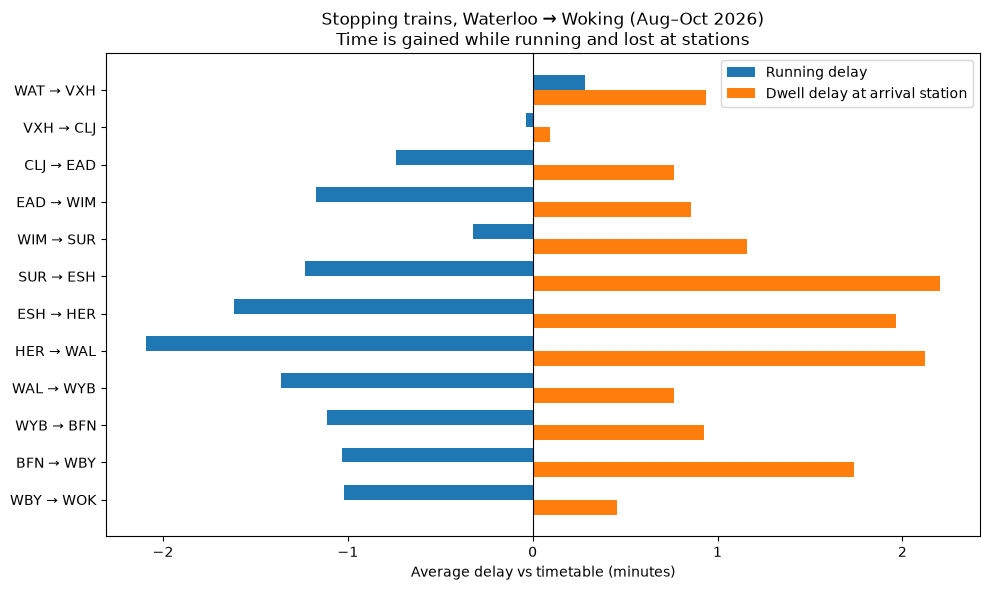

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
y = range(len(summary))

ax.barh([i - 0.2 for i in y], summary["run_delay"], height=0.4, label="Running delay")
ax.barh([i + 0.2 for i in y], summary["dwell_delay"], height=0.4, label="Dwell delay at arrival station")

ax.set_yticks(list(y))
ax.set_yticklabels(summary["section"])
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Average delay vs timetable (minutes)")
ax.set_title("Stopping trains, Waterloo → Woking (Aug–Oct 2026)\nTime is gained while running and lost at stations")
ax.legend()
plt.tight_layout()

fig.savefig(config.FIG_DIR / "delay_by_section.png", dpi=150)
plt.show()